In [1]:
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv('collected_data_spring_2.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

df.head()

,Timestamp,Type,Name,CPU,Memory,Count
0,2024-03-18 09:48:39,Node,test-control-plane,481m,728Mi,1
1,2024-03-18 09:48:39,Pod,test-app-79645bbddb-b74x5,26m,22Mi,2
2,2024-03-18 09:48:39,Pod,test-app-79645bbddb-knz42,17m,25Mi,2
3,2024-03-18 09:49:40,Node,test-control-plane,683m,792Mi,1
4,2024-03-18 09:49:40,Pod,test-app-79645bbddb-b74x5,134m,23Mi,3


In [2]:
MAX_REPLICA_COUNT = df['Count'].max() + 1

replica_graphs = []

def get_replica_row(replica_num, group):
    if len(group) >= replica_num:
        return group.iloc[replica_num-1:replica_num]

grouped = df.groupby('Timestamp')

node_stats = grouped.apply(lambda x: x.iloc[0]).reset_index(drop=True)
pod_stats = grouped.apply(lambda x: x.iloc[1]).reset_index(drop=True)

node_stats['Memory'] = node_stats['Memory'].str.split("Mi").apply(lambda x: int(x[0]))

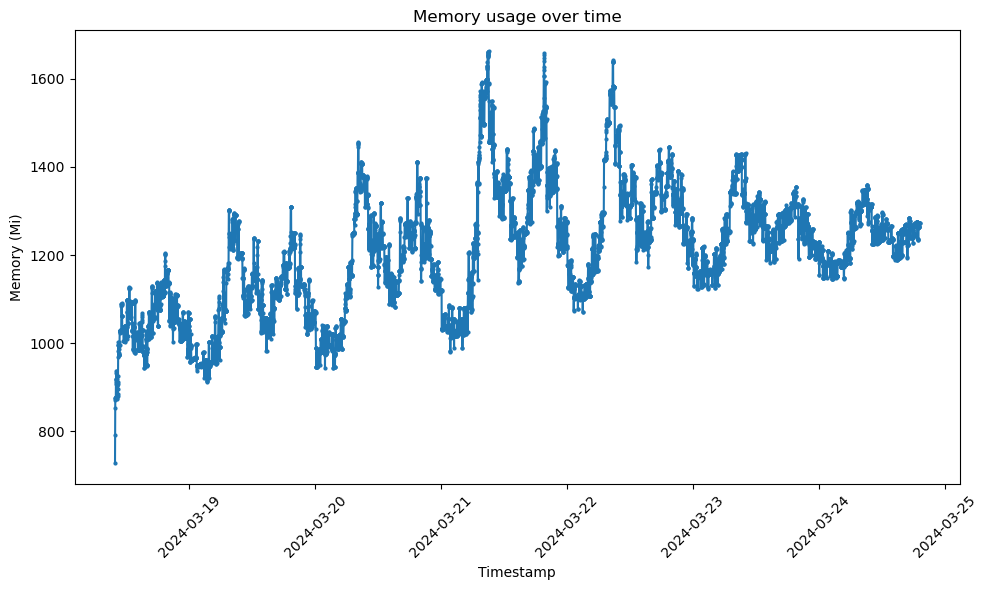

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(node_stats.sort_values(by='Timestamp')['Timestamp'], node_stats['Memory'], marker='o', markersize = 2, linestyle='-')
plt.title('Memory usage over time')
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')
plt.xticks(rotation=45)  
plt.tight_layout()  
plt.show()

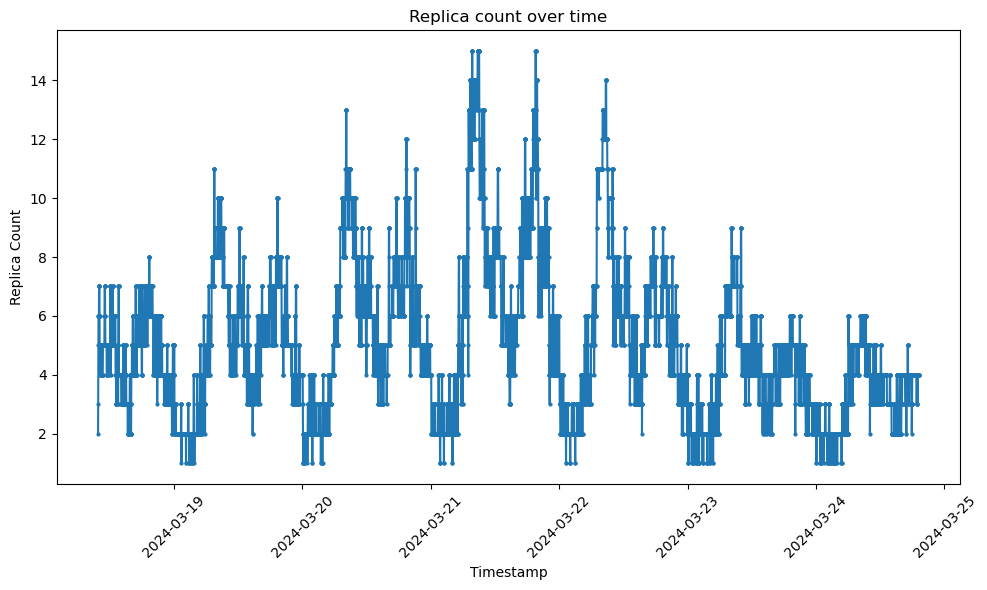

In [5]:
plt.figure(figsize=(10, 6))
plt.plot(pod_stats.sort_values(by='Timestamp')['Timestamp'], pod_stats['Count'], marker='o', markersize = 2, linestyle='-')
plt.title('Replica count over time')
plt.xlabel('Timestamp')
plt.ylabel('Replica Count')
plt.xticks(rotation=45)  
plt.tight_layout()  
plt.show()